In [9]:
# import openai
import os

import json
import argparse
import tqdm
import time
import textstat

import re
import pickle

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import prettytable
from prettytable import PrettyTable
from scipy.stats import spearmanr, pearsonr, kendalltau
import torch
from transformers import GPT2Tokenizer, GPT2LMHeadModel
import math


from collections import Counter
from typing import List, Tuple

from collections import defaultdict

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import torch.nn.functional as F

from tqdm import tqdm

from transformers import AutoTokenizer, AutoModelForCausalLM


In [10]:
print('a')

a


In [11]:
summeval_fp = '/users/data/summeval.json'



input_fp_rel1 = '/users/results/sum/sum_RE_gpt-4.1-nano_temp1_n20.json' #--price = 0.10
input_fp_rel2 = '/users/all_data/results/sum/sum_RE_gpt-4.1-mini_temp1_n20.json' #--price = 0.40
input_fp_rel3 = '/users/all_data/results/sum/sum_RE_gpt-4o-mini_temp1_n20.json' #--price = 0.15
input_fp_rel4 = '/users/all_data/results/gpt4_rel_detailed.json'

input_fp_coh1 = '/users/all_data/results/sum/sum_CH_gpt-4.1-nano_temp1_n20.json' 
input_fp_coh2 = '/users/all_data/results/sum/sum_CH_gpt-4.1-mini_temp1_n20.json' 
input_fp_coh3 = '/users/all_data/results/sum/sum_CH_gpt-4o-mini_temp1_n20.json' 
input_fp_coh4 = '/users/all_data/results/gpt4_coh_detailed.json'


saving_path = '/users/all_data/results/figures'

In [12]:
def parse_output(output):
    matched = re.search("^ ?([\d\.]+)", output)
    if (matched):
        try:
            score = float(matched.group(1))
        except:
            score = 0
    else:
        score = 0
    return score
    
def measure_all_scores(input_fp, dimension='relevance'):
    ''' measure linguistic complexity ''' 
    with open(input_fp, 'r', encoding='utf-8') as f:
        jobj = json.load(f)

    model_scores, human_scores = {}, {}
    readability_scores = {}

    for item in jobj:
        doc_id = item["doc_id"]

        if doc_id not in model_scores:
            model_scores[doc_id] = []
            human_scores[doc_id] = []
            readability_scores[doc_id] = []

        # Model score
        all_responses = item["all_responses"]
        all_scores = [parse_output(x) for x in all_responses]
        score = sum(all_scores) / len(all_scores)

        model_scores[doc_id].append(score)
        human_scores[doc_id].append(item['scores'][dimension])

        # Readability measurement
        paragraph = item.get("system_output", "").strip()
        if paragraph:
            readability = {
                'flesch_reading_ease': textstat.flesch_reading_ease(paragraph),
                'flesch_kincaid_grade': textstat.flesch_kincaid_grade(paragraph),
                'gunning_fog': textstat.gunning_fog(paragraph),
                'smog_index': textstat.smog_index(paragraph),
                'automated_readability_index': textstat.automated_readability_index(paragraph),
                'dale_chall_score': textstat.dale_chall_readability_score(paragraph),
                'difficult_words': textstat.difficult_words(paragraph),
                'lexicon_count': textstat.lexicon_count(paragraph),
                'syllable_count': textstat.syllable_count(paragraph),
            }
            readability_scores[doc_id].append(readability)


    return model_scores, human_scores, readability_scores


<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_1119239/878826776.py:2: SyntaxWarning: invalid escape sequence '\d'
  matched = re.search("^ ?([\d\.]+)", output)


In [14]:
model_scores_rel1, human_scores_rel, red_scores_rel = measure_all_scores(input_fp_rel1, dimension = 'relevance')
model_scores_rel2, _, _ = measure_all_scores(input_fp_rel2, dimension = 'relevance')
model_scores_rel3, _, _ = measure_all_scores(input_fp_rel3, dimension = 'relevance')
model_scores_rel4, _, _ = measure_all_scores(input_fp_rel4, dimension = 'relevance')

model_scores_coh1, human_scores_coh, red_scores_coh = measure_all_scores(input_fp_coh1, dimension = 'coherence')
model_scores_coh2, _, _ = measure_all_scores(input_fp_coh2, dimension = 'coherence')
model_scores_coh3, _, _ = measure_all_scores(input_fp_coh3, dimension = 'coherence')
model_scores_coh4, _, _ = measure_all_scores(input_fp_coh4, dimension = 'coherence')




In [15]:
len(model_scores_coh1)

100

In [16]:
model_name ="microsoft/phi-2"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name, device_map="auto")

model.eval()

def conditional_perplexity(S1, S2): #S1: summary, S2: context (source) p(S1|S1+S2) 
    full_input = S2 + " " + S1
    S2_ids = tokenizer(S2, return_tensors="pt").input_ids.to(model.device)
    full_ids = tokenizer(full_input, return_tensors="pt").input_ids.to(model.device)
    with torch.no_grad():
        outputs = model(full_ids, labels=full_ids)
        logits = outputs.logits

    S2_len = S2_ids.size(1)
    shift_logits = logits[:, S2_len-1:-1, :]
    shift_labels = full_ids[:, S2_len:]

    loss_fct = torch.nn.CrossEntropyLoss(ignore_index=-100)
    loss = loss_fct(shift_logits.view(-1, shift_logits.size(-1)),
                    shift_labels.view(-1))
    return math.exp(-loss.item())

def conditional_perplexity_s2_only(S1, S2): #p(S1|S2)
    # Tokenize S2 and S1 separately
    S2_ids = tokenizer(S2, return_tensors="pt").input_ids.to(model.device)
    S1_ids = tokenizer(S1, return_tensors="pt").input_ids.to(model.device)

    # Combine S2 + S1 for model input
    full_ids = torch.cat([S2_ids, S1_ids], dim=1)

    # Prepare labels: S2 tokens are ignored, S1 tokens are the target
    labels = full_ids.clone()
    labels[:, :S2_ids.size(1)] = -100  # Ignore S2 tokens -- The model tries to predict S1

    # Run model
    with torch.no_grad():
        outputs = model(full_ids, labels=labels)
        loss = outputs.loss  # Cross-entropy loss is automatically computed

    return math.exp(-loss.item())


Loading checkpoint shards: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [01:28<00:00, 44.02s/it]


In [17]:
def measure_all_condprep(input_fp, dimension='relevance'):
    ''' measure linguistic complexity '''
    with open(input_fp, 'r', encoding='utf-8') as f:
        jobj = json.load(f)

    model_scores, human_scores, condprep1, condprep2 = {}, {}, {}, {}

    # for idx,item in enumerate(jobj):
    for idx, item in tqdm(enumerate(jobj), total=len(jobj)):
        # print(f"item: {idx} ")
        doc_id = item["doc_id"]
        # print(doc_id)
        if doc_id not in model_scores:
            model_scores[doc_id] = []
            human_scores[doc_id] = []
            condprep1[doc_id] = []
            condprep2[doc_id] = []
            
        # Model score
        all_responses = item["all_responses"]
        all_scores = [parse_output(x) for x in all_responses]
        score = sum(all_scores) / len(all_scores)

        model_scores[doc_id].append(score)
        human_scores[doc_id].append(item['scores'][dimension])

        # entropy measurement
        paragraph_summary = item.get("system_output", "").strip() #based on summary
        paragraph_source = item.get("source", "").strip() # based on input

        if paragraph_source and paragraph_summary:
            cp1 = conditional_perplexity(paragraph_summary, paragraph_source)
            cp2 = conditional_perplexity_s2_only(paragraph_summary, paragraph_source)

   
            condprep1[doc_id].append(cp1)
            condprep2[doc_id].append(cp2)

    return model_scores, human_scores, condprep1, condprep2



In [18]:
_, _, condprep_rel1, condprep_rel2 = measure_all_condprep(input_fp_rel1, dimension = 'relevance')
_, _, condprep_coh1, condprep_coh2 = measure_all_condprep(input_fp_coh1, dimension = 'coherence')


In [19]:

# conditioned on summary-source (S1S2) and summary only (S2)
load_dir = '/users/faculty/sadeghi/exps/botval/results'
file_path = os.path.join(load_dir, 'condprep_phi_S2.pkl')
with open(file_path, 'rb') as file:
    condprep_rel2, condprep_coh2 = pickle.load(file)

# used in the paper
load_dir = '/users/faculty/sadeghi/exps/botval/results'
file_path = os.path.join(load_dir, 'condprep_phi_S1S2.pkl')
with open(file_path, 'rb') as file:
    condprep_rel1, condprep_coh1 = pickle.load(file)

In [20]:
from collections import Counter

def gini_index(sentence):
    words = sentence.lower().split()
    total = len(words)
    if total == 0:
        return 0.0

    counts = Counter(words)
    probs = [count / total for count in counts.values()]
    gini = 1 - sum(p ** 2 for p in probs)
    return gini



In [21]:
def compute_entropy_from_loss(text, model_name="gpt2"):


    model_name ="microsoft/phi-2"
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForCausalLM.from_pretrained(model_name, device_map="auto")

    # Encode input
    inputs = tokenizer(text, return_tensors="pt")
    input_ids = inputs["input_ids"]

    with torch.no_grad():
        outputs = model(input_ids, labels=input_ids)
        log_likelihood = outputs.loss  # average negative log likelihood (in nats)


    entropy = log_likelihood.item() / math.log(2)
    perplexity = 2 ** (-log_likelihood.item() / math.log(2))

    # print('ent','prep',entropy,perplexity)
    return entropy, perplexity


In [22]:
# instead of loading entropies, let's compute them here

def calculate_entropy_from_stat(text):
    # Basic word tokenization (splits on non-word characters)
    words = re.findall(r'\b\w+\b', text.lower())

    # Count word frequencies
    word_counts = Counter(words)
    total_words = len(words)

    # Calculate word probabilities
    probabilities = [count / total_words for count in word_counts.values()]

    # Calculate entropy
    entropy = -sum(p * math.log2(p) for p in probabilities)
    perplexity = 2 ** entropy
    return entropy, perplexity





In [27]:
def measure_all_entropy(input_fp, dimension='relevance'):
    ''' measure linguistic complexity '''
    with open(input_fp, 'r', encoding='utf-8') as f:
        jobj = json.load(f)

    model_scores, human_scores, entropy_source, prep_source, entropy_summary, prep_summary = {}, {}, {}, {}, {}, {}
    gini_source, gini_summary = {}, {}
    for idx,item in enumerate(jobj):
        # print(f"item: {idx} ")
        doc_id = item["doc_id"]
        # print(doc_id)
        if doc_id not in model_scores:
            model_scores[doc_id] = []
            human_scores[doc_id] = []
            entropy_source[doc_id] = []
            prep_source[doc_id] = []
            entropy_summary[doc_id] = []
            prep_summary[doc_id] = []
            gini_source[doc_id] = []
            gini_summary[doc_id] = []
        # Model score
        all_responses = item["all_responses"]
        all_scores = [parse_output(x) for x in all_responses]
        score = sum(all_scores) / len(all_scores)

        model_scores[doc_id].append(score)
        human_scores[doc_id].append(item['scores'][dimension])

        # entropy measurement
        paragraph_summary = item.get("system_output", "").strip() #based on summary
        paragraph_source = item.get("source", "").strip() # based on input

        if paragraph_source:
            # print('source')
            # text_entropy,text_prep = compute_entropy_from_loss(paragraph, model_name="gpt2")
            text_entropy,text_prep = calculate_entropy_from_stat(paragraph_source)
            entropy_source[doc_id].append(text_entropy)
            prep_source[doc_id].append(text_prep)
            gini_source[doc_id].append(gini_index(paragraph_source))
            
        if paragraph_summary:
            # print('summary')
            # text_entropy,text_prep = compute_entropy_from_loss(paragraph, model_name="gpt2")
            text_entropy,text_prep = calculate_entropy_from_stat(paragraph_summary)
            entropy_summary[doc_id].append(text_entropy)
            prep_summary[doc_id].append(text_prep)
            gini_summary[doc_id].append(gini_index(paragraph_summary))

    return model_scores, human_scores, entropy_source, prep_source, entropy_summary, prep_summary, gini_source, gini_summary

def parse_output(output):
    matched = re.search("^ ?([\d\.]+)", output)
    if (matched):
        try:
            score = float(matched.group(1))
        except:
            score = 0
    else:
        score = 0
    return score

<>:52: SyntaxWarning: invalid escape sequence '\d'
<>:52: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_1119239/3723343013.py:52: SyntaxWarning: invalid escape sequence '\d'
  matched = re.search("^ ?([\d\.]+)", output)


In [28]:


_, _, ent_source_rel1, prep_source_rel1, ent_sum_rel1, prep_sum_rel1, gini_source_rel1, gini_sum_rel1 = measure_all_entropy(input_fp_rel1, dimension = 'relevance')


_, _, ent_source_coh1, prep_source_coh1, ent_sum_coh1, prep_sum_coh1, gini_source_coh1, gini_sum_coh1 = measure_all_entropy(input_fp_coh1, dimension = 'coherence')



In [ ]:
# ----- load the results

load_dir = '/users/faculty/sadeghi/exps/botval/results'
file_path = os.path.join(load_dir, 'all_feat_rel.pkl')
with open(file_path, 'rb') as file:
    ent_source_rel1, prep_source_rel1, ent_sum_rel1, prep_sum_rel1, gini_source_rel1, gini_sum_rel1 = pickle.load(file)

file_path = os.path.join(load_dir, 'all_feat_coh.pkl')
with open(file_path, 'rb') as file:
    ent_source_coh1, prep_source_coh1, ent_sum_coh1, prep_sum_coh1, gini_source_coh1, gini_sum_coh1 = pickle.load(file)



In [35]:
def add_new_feature(data, new_feature_values, feature_name='new_feat'):
    for doc_id in new_feature_values:
        if doc_id not in data:
            print(f"Warning: doc_id {doc_id} in new_feature but not in data. Skipping.")
            continue

        doc_data = data[doc_id]
        new_values = new_feature_values[doc_id]

        if len(doc_data) != len(new_values):
            print(f"Warning: Length mismatch for doc_id {doc_id}. Skipping.")
            continue

        for i, value in enumerate(new_values):
            doc_data[i][feature_name] = float(value)  # Convert np.float32 to float
    
    return data


In [30]:

load_dir = '/users/faculty/sadeghi/exps/all_data/results'

file_path = os.path.join(load_dir, 'inp_out_sim_st_scores_rel.pkl')
with open(file_path, 'rb') as file:
    model_scores_rel, human_scores_rel, cos_sim_rel, cca_sim_rel = pickle.load(file)

cosim = cos_sim_rel

In [70]:
all_features_rel = {};all_features_coh = {}; all_features_con = {}


In [71]:
## Note ## cos_sim are the same for all dimensionalities
all_features_rel = add_new_feature(red_scores_rel, cosim, feature_name='cosine_sim')
all_features_coh = add_new_feature(red_scores_coh, cosim, feature_name='cosine_sim')



In [73]:
all_features_rel = add_new_feature(all_features_rel, ent_sum_rel1, feature_name='entropy_summary')
all_features_coh = add_new_feature(all_features_coh, ent_sum_coh1, feature_name='entropy_summary')


In [74]:
all_features_rel = add_new_feature(all_features_rel, prep_sum_rel1, feature_name='perplexity_summary')
all_features_coh = add_new_feature(all_features_coh, prep_sum_coh1, feature_name='perplexity_summary')



In [76]:
all_features_rel = add_new_feature(all_features_rel, gini_sum_rel1, feature_name='gini_summary')
all_features_coh = add_new_feature(all_features_coh, gini_sum_coh1, feature_name='gini_summary')


In [79]:
# P(S1|S1,S2)
all_features_rel = add_new_feature(all_features_rel, condprep_rel1, feature_name='conditional perplexity')
all_features_coh = add_new_feature(all_features_coh, condprep_coh1, feature_name='conditional perplexity')



In [82]:
def calculate_correlation(pred_score, human_score, result):
    assert len(pred_score) == len(human_score)
    if (len(result) == 0):
        result = {'pearson': 0, 'pearson_p': 0,
            'spearman': 0, 'spearman_p': 0,
            'kendalltau': 0, 'kendalltau_p': 0}
    
    r_pearson, p_pearson = pearsonr(pred_score, human_score)
    r_spearman, p_spearman = spearmanr(pred_score, human_score)
    r_kendall, p_kendall = kendalltau(pred_score, human_score)

    # print('p_pearson',p_pearson)
    # print('p_spearman',p_spearman)
    # print('p_kendall',p_kendall)

    # Accumulate correlation values and p-values
    result['pearson'] += r_pearson
    result['pearson_p'] += p_pearson
    result['spearman'] += r_spearman
    result['spearman_p'] += p_spearman
    result['kendalltau'] += r_kendall
    result['kendalltau_p'] += p_kendall

    return result

# def calculate_correlation(values, scores):
#     if len(values) != len(scores):
#         raise ValueError("Mismatched lengths between values and scores.")
#     corr, p_value = pearsonr(values, scores)
#     # corr, p_value = spearmanr(values, scores)
#     # corr, p_value = kendalltau(values, scores)

#     return corr, p_value
    
def print_correlations(result, n):

    table = PrettyTable(['Metric', 'Correlation', 'p-value'])
    table.add_row(['Pearson', round(result['pearson'] / n, 4), round(result['pearson_p'] / n, 4)])
    table.add_row(['Spearman', round(result['spearman'] / n, 4), round(result['spearman_p'] / n, 4)])
    table.add_row(['Kendall', round(result['kendalltau'] / n, 4), round(result['kendalltau_p'] / n, 4)])
    
    print(table)


def parse_output(output):
    matched = re.search("^ ?([\d\.]+)", output)
    if (matched):
        try:
            score = float(matched.group(1))
        except:
            score = 0
    else:
        score = 0
    return score

<>:46: SyntaxWarning: invalid escape sequence '\d'
<>:46: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_1119239/2877143987.py:46: SyntaxWarning: invalid escape sequence '\d'
  matched = re.search("^ ?([\d\.]+)", output)


In [83]:
from collections import defaultdict

def compute_feature_correlations(data, human_scores, pred_scores):
    """
    data: dict[doc_id] -> list of dicts (features per item)
    human_scores: dict[doc_id] -> list of human ratings
    pred_scores: dict[doc_id] -> list of model ratings
    """
    # Results dictionary: one result dict per feature per target (human/model)Cohesion
    feature_results = defaultdict(lambda: {'human': {}, 'model': {}, 'count': 0})

    # we calculate correlation for each doc_id which is a vector of size 16
    for i, doc_id in enumerate(data):
        doc_features = data[doc_id]
        human = human_scores[doc_id]
        model = pred_scores[doc_id]

        # Sanity check
        if len(doc_features) != len(human) or len(doc_features) != len(model):
            print(f"Skipping doc {doc_id} due to mismatched lengths.")
            continue

        # Extract list of feature names
        feature_keys = doc_features[0].keys()
        # print(feature_keys)
        for feature in feature_keys:
            # Get feature values across all items in the doc
            try:
                values = [item[feature] for item in doc_features]
            except KeyError:
                continue

            # print('values',len(values))
            # print('human',len(human))
            # print('model',len(model))
    
            ##Skip if feature has no variation
            if len(set(values)) <= 1:
                print(f'no variation for {feature} and doc {i}')
                print(values)

                continue

            # Only compute correlation if human/model scores vary
            if len(set(human)) > 1:
                feature_results[feature]['human'] = calculate_correlation(values, human, feature_results[feature]['human'])
                
                
            if len(set(model)) > 1:
                feature_results[feature]['model'] = calculate_correlation(values, model, feature_results[feature]['model'])
              

            feature_results[feature]['count'] += 1

    return feature_results


In [84]:
from collections import defaultdict

def compute_feature_avg_correlations(data, human_scores, pred_scores):
    """
    data: dict[doc_id] -> list of dicts (features per item)
    human_scores: dict[doc_id] -> list of human ratings
    pred_scores: dict[doc_id] -> list of model ratings
    """
    # Results dictionary: one result dict per feature per target (human/model)Cohesion
    feature_results = defaultdict(lambda: {'human': {}, 'model': {}, 'count': 0})

    # we calculate correlation for each doc_id which is a vector of size 16
    for i, doc_id in enumerate(data):
        doc_features = data[doc_id]
        human = human_scores[doc_id]
        model = pred_scores[doc_id]

        # Sanity check
        if len(doc_features) != len(human) or len(doc_features) != len(model):
            print(f"Skipping doc {doc_id} due to mismatched lengths.")
            continue

        # Extract list of feature names
        feature_keys = doc_features[0].keys()
        # print(feature_keys)
        for feature in feature_keys:
            # Get feature values across all items in the doc
            try:
                values = [item[feature] for item in doc_features]
            except KeyError:
                continue

            # print('values',len(values))
            # print('human',len(human))
            # print('model',len(model))
    
            ##Skip if feature has no variation
            if len(set(values)) <= 1:
                print(f'no variation for {feature} and doc {i}')
                print(values)

                continue

            # Only compute correlation if human/model scores vary
            if len(set(human)) > 1:
                feature_results[feature]['human'] = calculate_correlation(values, human, feature_results[feature]['human'])
                
                
            if len(set(model)) > 1:
                feature_results[feature]['model'] = calculate_correlation(values, model, feature_results[feature]['model'])
              

            feature_results[feature]['count'] += 1

    return feature_results


In [85]:
def compute_feature_overall_correlations(all_features, human_scores, model_scores1,model_scores2,model_scores3,model_scores4):
    feature_results = defaultdict(lambda: {'human': {}, 'gpt1': {} , 'gpt2': {}, 'gpt3': {}, 'gpt4': {}})
    human_vals = []
    model_vals1,model_vals2,model_vals3,model_vals4 = [],[],[],[]
    # we calculate correlation for each doc_id which is a vector of size 16
    for doc_id in all_features:
        human_vals += human_scores[doc_id]
        model_vals1 += model_scores1[doc_id]
        model_vals2 += model_scores2[doc_id]
        model_vals3 += model_scores3[doc_id]
        model_vals4 += model_scores4[doc_id]
        
    # print('len after',len(human))
    # print('len after',len(model))

    first_value = next(iter(all_features.values()))
    feature_keys = list(first_value[0].keys())
    print(feature_keys)
    for feature in feature_keys:
        f_values = []
        for doc_id in all_features:
            doc_features = all_features[doc_id]     
            values = [item[feature] for item in doc_features]
            f_values += values
        # print(len(f_values))
        corrp_human, pvalp_human = pearsonr(f_values, human_vals)
        feature_results[feature]['human']['pearson'] = corrp_human
        feature_results[feature]['human']['pearson_p'] = pvalp_human
        corrs_human, pvals_human = spearmanr(f_values, human_vals)
        feature_results[feature]['human']['spearman'] = corrs_human
        feature_results[feature]['human']['spearman_p'] = pvals_human
        corrt_human, pvalt_human = kendalltau(f_values, human_vals)
        feature_results[feature]['human']['kendalltau'] = corrt_human
        feature_results[feature]['human']['kendalltau_p'] = pvalt_human

        corrp_model, pvalp_model = pearsonr(f_values, model_vals1)
        feature_results[feature]['gpt1']['pearson'] = corrp_model
        feature_results[feature]['gpt1']['pearson_p'] = pvalp_model
        corrs_model, pvals_model = spearmanr(f_values, model_vals1)
        feature_results[feature]['gpt1']['spearman'] = corrs_model
        feature_results[feature]['gpt1']['spearman_p'] = pvals_model
        corrt_model, pvalt_model = kendalltau(f_values, model_vals1)
        feature_results[feature]['gpt1']['kendalltau'] = corrt_model
        feature_results[feature]['gpt1']['kendalltau_p'] = pvalt_model

        corrp_model, pvalp_model = pearsonr(f_values, model_vals2)
        feature_results[feature]['gpt2']['pearson'] = corrp_model
        feature_results[feature]['gpt2']['pearson_p'] = pvalp_model
        corrs_model, pvals_model = spearmanr(f_values, model_vals2)
        feature_results[feature]['gpt2']['spearman'] = corrs_model
        feature_results[feature]['gpt2']['spearman_p'] = pvals_model
        corrt_model, pvalt_model = kendalltau(f_values, model_vals2)
        feature_results[feature]['gpt2']['kendalltau'] = corrt_model
        feature_results[feature]['gpt2']['kendalltau_p'] = pvalt_model

        corrp_model, pvalp_model = pearsonr(f_values, model_vals3)
        feature_results[feature]['gpt3']['pearson'] = corrp_model
        feature_results[feature]['gpt3']['pearson_p'] = pvalp_model
        corrs_model, pvals_model = spearmanr(f_values, model_vals3)
        feature_results[feature]['gpt3']['spearman'] = corrs_model
        feature_results[feature]['gpt3']['spearman_p'] = pvals_model
        corrt_model, pvalt_model = kendalltau(f_values, model_vals3)
        feature_results[feature]['gpt3']['kendalltau'] = corrt_model
        feature_results[feature]['gpt3']['kendalltau_p'] = pvalt_model

        corrp_model, pvalp_model = pearsonr(f_values, model_vals4)
        feature_results[feature]['gpt4']['pearson'] = corrp_model
        feature_results[feature]['gpt4']['pearson_p'] = pvalp_model
        corrs_model, pvals_model = spearmanr(f_values, model_vals4)
        feature_results[feature]['gpt4']['spearman'] = corrs_model
        feature_results[feature]['gpt4']['spearman_p'] = pvals_model
        corrt_model, pvalt_model = kendalltau(f_values, model_vals4)
        feature_results[feature]['gpt4']['kendalltau'] = corrt_model
        feature_results[feature]['gpt4']['kendalltau_p'] = pvalt_model
    return feature_results

In [86]:
def print_feature_correlation_results(results):
    for feature, result_dict in results.items():
      
        print(f"\nFeature: {feature}")
        for target in ['human', 'gpt1','gpt2','gpt3','gpt4']:
            if result_dict.get(target):
                print(f"  With {target} scores:")
                print(f"    Pearson:    {result_dict[target]['pearson']:.5f} "
                      f"(p={result_dict[target]['pearson_p']:.5f})")
                print(f"    Spearman:   {result_dict[target]['spearman']:.5f} "
                      f"(p={result_dict[target]['spearman_p']:.5f})")
                print(f"    KendallTau: {result_dict[target]['kendalltau']:.5f} "
                      f"(p={result_dict[target]['kendalltau_p']:.5f})")


In [88]:
results_rel = compute_feature_overall_correlations(all_features_rel, human_scores_rel, model_scores_rel1,model_scores_rel2,model_scores_rel3,model_scores_rel4)
# print_feature_correlation_results(results_rel)


['flesch_reading_ease', 'flesch_kincaid_grade', 'gunning_fog', 'smog_index', 'automated_readability_index', 'dale_chall_score', 'difficult_words', 'lexicon_count', 'syllable_count', 'cosine_sim', 'entropy_summary', 'perplexity_summary', 'gini_summary', 'conditional perplexity']


In [90]:
results_coh = compute_feature_overall_correlations(all_features_coh, human_scores_coh, model_scores_coh1,model_scores_coh2,model_scores_coh3,model_scores_coh4)
# print_feature_correlation_results(results_coh)

['flesch_reading_ease', 'flesch_kincaid_grade', 'gunning_fog', 'smog_index', 'automated_readability_index', 'dale_chall_score', 'difficult_words', 'lexicon_count', 'syllable_count', 'cosine_sim', 'entropy_summary', 'perplexity_summary', 'gini_summary', 'conditional perplexity']


In [186]:
import matplotlib.pyplot as plt
import numpy as np

def barplot_feature_correlations_sorted(results, filename, corr_type='spearman', sort_by='gpt4',dim='Not specified'):
    """
    Bar plot of correlations for each feature with human and model scores.
    
    Parameters:
    - results: dict of correlation results from compute_feature_correlations_with_existing_fn
    - corr_type: 'pearson', 'spearman', or 'kendalltau'
    - sort_by: 'human' or 'model' — determines sorting key
    """
    features = []
    human_corrs = []
    model_corrs1,model_corrs2,model_corrs3,model_corrs4 = [],[],[],[]

    # Collect and sort data
    sortable = []
    for feature, result in results.items():

        if corr_type not in result['human'] or corr_type not in result['gpt4']:
            print('error')
            continue

        human_val = result['human'][corr_type]
        model_val1 = result['gpt1'][corr_type]
        model_val2 = result['gpt2'][corr_type]
        model_val3 = result['gpt3'][corr_type]
        model_val4 = result['gpt4'][corr_type]

        sortable.append((feature, human_val, model_val1, model_val2, model_val3, model_val4))

    # Sort by specified correlation
    if sort_by == 'human':
        sortable.sort(key=lambda x: x[1], reverse=True)
    elif sort_by == 'gpt4':
        sortable.sort(key=lambda x: x[5], reverse=True)

    for feature, human_val, model_val1, model_val2, model_val3, model_val4 in sortable:
        features.append(feature)
        human_corrs.append(human_val)
        model_corrs1.append(model_val1)
        model_corrs2.append(model_val2)
        model_corrs3.append(model_val3)
        model_corrs4.append(model_val4)


    # Bar plot
    x = np.arange(len(features))
    width = 0.1


    # colors = [ 
    #     '#c6dbef',  # Light Blue
    #     '#9ecae1',  # Soft Blue
    #     '#6baed6',  # Medium Blue
    #     '#1f77b4',#Electric Blue   
    #     '#f28e2b', #Burnt Orange     
    #     '#a1d99b',  # light green
    #     '#74c476',  # medium-light green
    #     '#41ab5d',  # medium green
    #     '#238b45',  # dark green
    #     '#005a32']  # very dark green
    colors = [
    '#1f77b4',  # strong blue
    '#ff7f0e',  # bright orange
    '#2ca02c',  # clean green
    '#d62728',  # strong red
    '#9467bd',  # purple
]

  
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - 2*width, human_corrs, width, label='Human', color=colors[0])
    ax.bar(x - width,   model_corrs1, width, label='gpt-4.1-nano', color=colors[1])
    ax.bar(x,           model_corrs2, width, label='gpt-4.1-mini', color=colors[2])
    ax.bar(x + width,   model_corrs3, width, label='gpt-4o-mini', color=colors[3])
    ax.bar(x + 2*width, model_corrs4, width, label='gpt-4-0613', color=colors[4])

    ax.axhline(y=0.3, color='black', linestyle='--')

    # Labels and legend
    ax.set_ylabel(f'{corr_type.capitalize()} Correlation')
    # ax.set_title(f'{corr_type.capitalize()} Correlation of Features with Human vs. Model Scores for {dim}')
    ax.set_xticks(x)
    ax.set_xticklabels(features, rotation=45, ha='right')
    ax.legend()
    ax.grid(True, axis='y', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig(filename, dpi=100)

    plt.show()



In [181]:
#results_rel

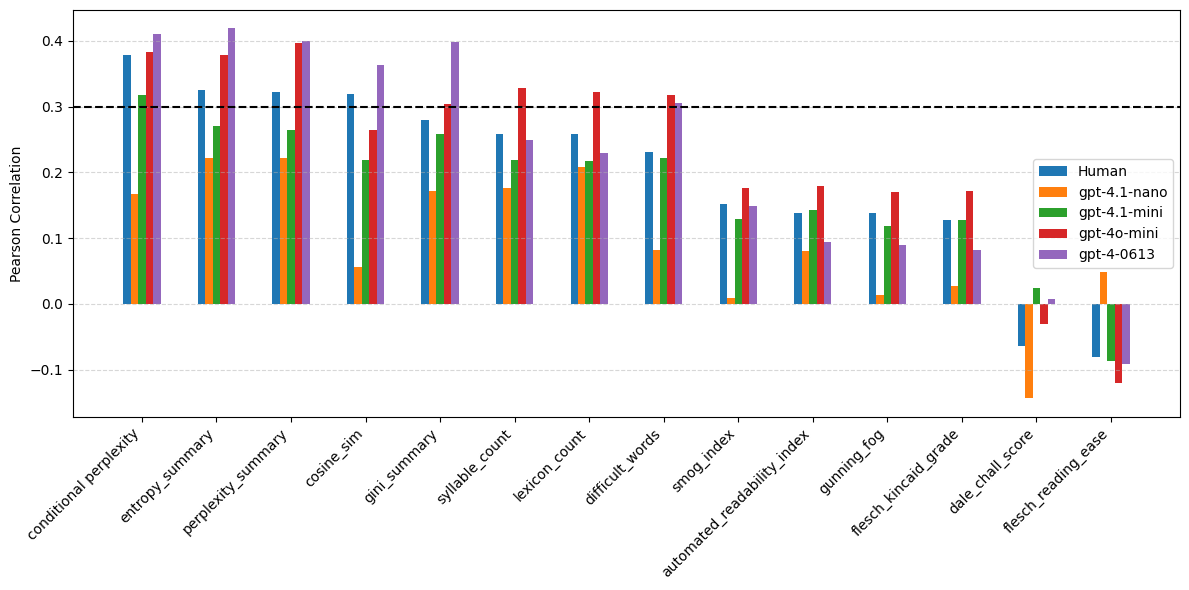

In [187]:
# phi -- - condprep12
filename = os.path.join(saving_path, "corr_barchart_cos_ent_gini_read_rel_gpts_phi_condprep1_2_clear.png")
barplot_feature_correlations_sorted(results_rel, filename, corr_type='pearson', sort_by='human',dim = 'Relevance')


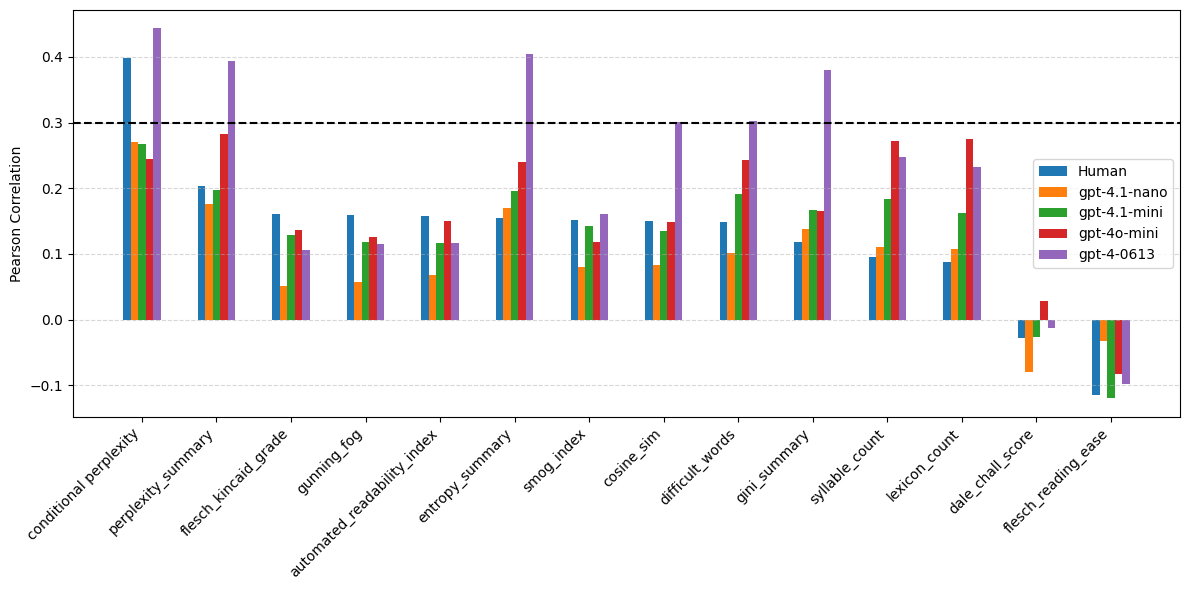

In [188]:
#phi condprep1 -- final P(S1|S1,S2)
filename = os.path.join(saving_path, "corr_barchart_cos_ent_gini_read_coh_gpts_phi_condprep1_clear.png")
barplot_feature_correlations_sorted(results_coh, filename, corr_type='pearson', sort_by='human',dim = 'Coherence')

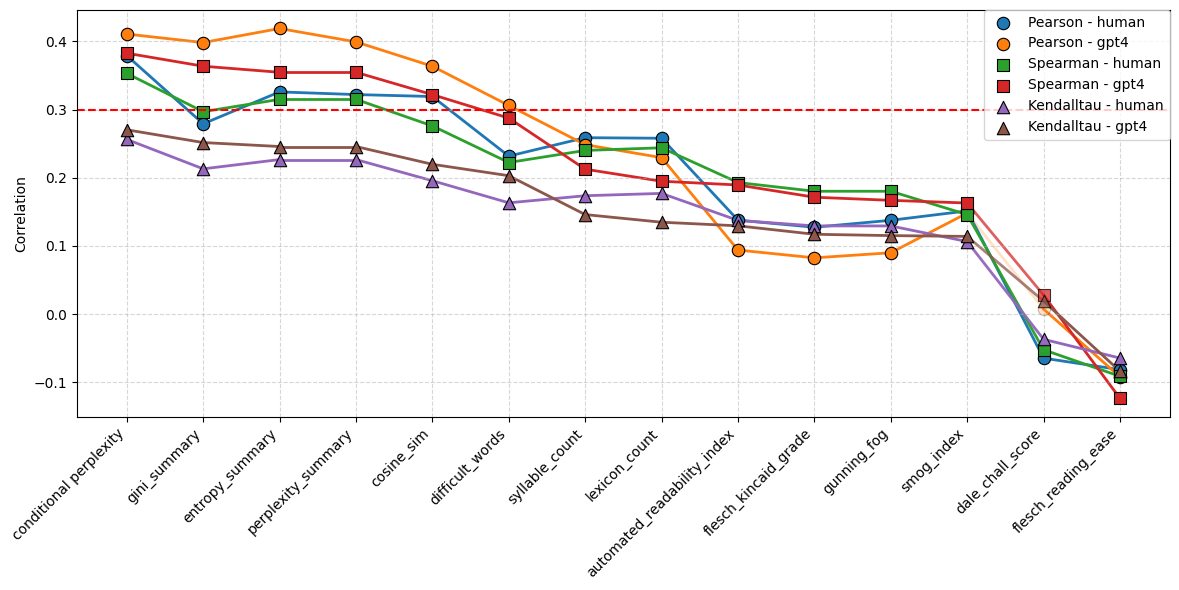

In [216]:
# revision
filename = os.path.join(saving_path, "corr_scatter_cos_ent_read_gini_rel_model_condprep1_legend_tau_clear.png")

plot_feature_correlations_scatter(results_rel, filename, sort_by=('kendalltau', 'gpt4'),dim = 'Relevance')
# we only consider correlations higher than 0.2 and lower than -0.2. Human show less correlations so we don't consider sorting based on human's

In [215]:
import matplotlib.pyplot as plt
import numpy as np

def plot_feature_correlations_scatter(results, filename, sort_by=('spearman', 'human'),dim = 'Not specified'):
    colors = ['#f28e2b',  '#005a32']
    corr_type_to_marker = {'pearson': 'o', 'spearman': 's', 'kendalltau': '^'}
    target_to_color = {'human': colors[0], 'gpt4': colors[1]}

    corr_type, target = sort_by

    # Filter and compute average correlation for sorting
    sortable_features = []
    for feature, result in results.items():
        # if result['count'] == 0 or target not in result or corr_type not in result[target]:
        #     continue
        avg_corr = result[target][corr_type] 
        sortable_features.append((feature, avg_corr))

    # Sort features based on chosen correlation
    sortable_features.sort(key=lambda x: x[1], reverse=True)
    sorted_features = [f[0] for f in sortable_features]
    x = np.arange(len(sorted_features))

    plt.figure(figsize=(14, 6))

    # Distinct colors for each (corr, tgt) series
    line_colors = [
        '#1f77b4',  # blue
        '#ff7f0e',  # orange
        '#2ca02c',  # green
        '#d62728',  # red
        '#9467bd',  # purple
        '#8c564b',  # brown
        '#e377c2',  # pink
        '#7f7f7f',  # gray
        '#bcbd22',  # olive
        '#17becf',  # cyan
    ]
    
    # Assign one color to each (corr, tgt) pair
    series_colors = {}
    idx = 0
    for corr in corr_type_to_marker:
        for tgt in target_to_color:
            series_colors[(corr, tgt)] = line_colors[idx % len(line_colors)]
            idx += 1
    
    # Store previous point for each series
    prev_points = {}
    
    for i, feature in enumerate(sorted_features):
        result = results[feature]
    
        for corr in corr_type_to_marker:
            for tgt in target_to_color:
    
                if tgt in result and corr in result[tgt]:
    
                    y_val = result[tgt][corr]
    
                    # Get p-value
                    p_key = f"{corr}_p"
                    p_val = result[tgt].get(p_key, 1.0)
    
                    # Map p-value to alpha
                    alpha = 1.0 - min(p_val, 1.0)
    
                    color = series_colors[(corr, tgt)]
    
                    key = (corr, tgt)
    
                    # Draw line from previous point
                    if key in prev_points:
                        prev_i, prev_y = prev_points[key]
    
                        plt.plot(
                            [prev_i, i],
                            [prev_y, y_val],
                            color=color,
                            linewidth=2,
                            alpha=alpha,
                            zorder=1
                        )
    
                    # Draw point
                    plt.scatter(
                        i,
                        y_val,
                        color=color,
                        marker=corr_type_to_marker[corr],
                        label=f"{corr.capitalize()} - {tgt}" if i == 0 else "",
                        s=80,
                        edgecolors='k',
                        linewidth=0.8,
                        alpha=alpha,
                        zorder=2
                    )
    
                    # Save current point
                    prev_points[key] = (i, y_val)
   

    # Axes and labels
    plt.axhline(y=0.3, color='red', linestyle='--')
    # plt.axhline(y=-0.3, color='red', linestyle='--')

    plt.xticks(x, sorted_features, rotation=45, ha='right')
    plt.ylabel("Correlation")
    # plt.title(f"Feature Correlations (sorted by {corr_type.capitalize()} - {target.capitalize()}) for {dim}")
    plt.grid(True, linestyle='--', alpha=0.5)

    # Legend outside plot
    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    plt.legend(
        by_label.values(),
        by_label.keys(),
        loc= 'upper right', #'center left',
        #bbox_to_anchor=(1.02, 0.5),
        borderaxespad=0,
        #title='Correlation Type'
    )

    plt.tight_layout(rect=[0, 0, 0.85, 1])
    plt.savefig(filename, dpi=100)

    plt.show()


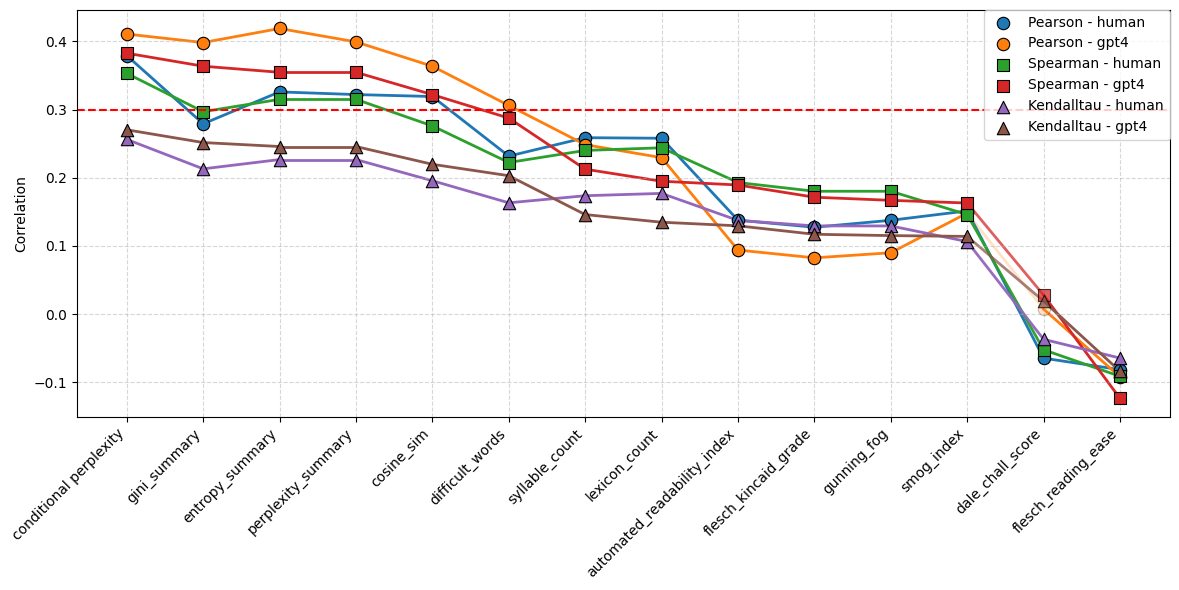

In [217]:
# final4 P(S1|S1,S2) --- revision
filename = os.path.join(saving_path, "corr_scatter_cos_ent_read_gini_rel_model_condprep1_legend_tau_clear.png")

plot_feature_correlations_scatter(results_rel, filename, sort_by=('kendalltau', 'gpt4'),dim = 'Relevance')
# we only consider correlations higher than 0.2 and lower than -0.2. Human show less correlations so we don't consider sorting based on human's

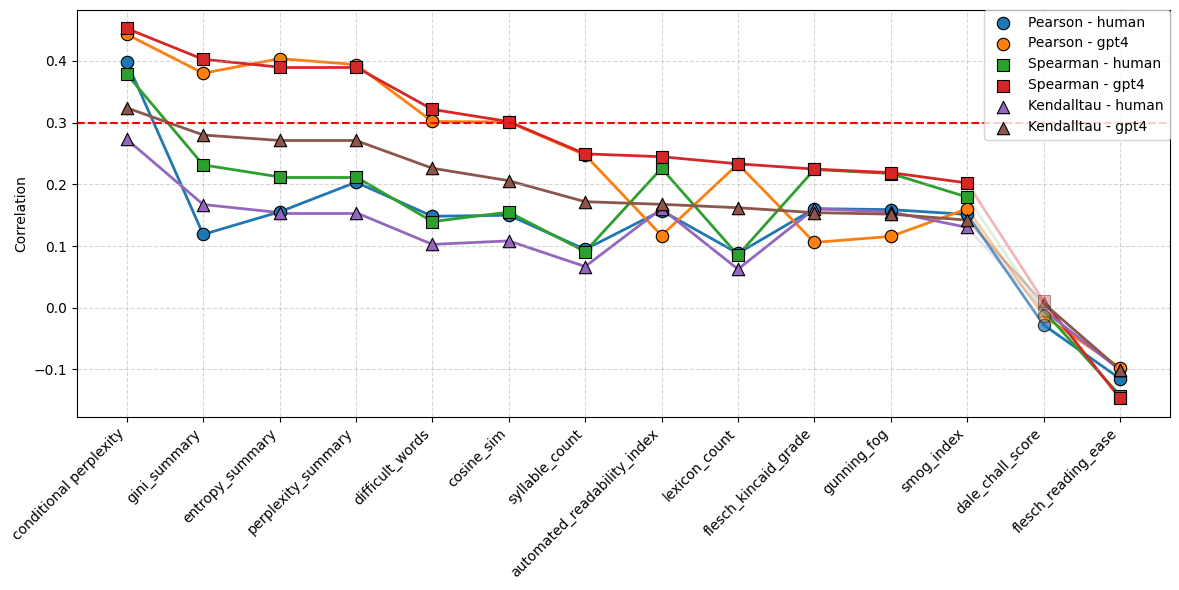

In [218]:
# final4 -- P(S1|S1,S2) --revision
filename = os.path.join(saving_path, "corr_scatter_cos_ent_read_gini_coh_model_condprep1_legend_tau_clear.png")

plot_feature_correlations_scatter(results_coh, filename, sort_by=('kendalltau', 'gpt4'),dim = 'Coherence')